# Effective dimension of single-vector datasets

Participation ratio (PR) of every dataset in `NPY_DATASETS`. Each is a directory holding `vectors.npy` (`n x d`, one point per row), `ids.npy` and `sq_norms.npy`. `ids.npy` is not needed. `sq_norms.npy` is checked against the first rows of `vectors.npy` and a warning is printed if they don't match.

For centred points $x_i$ with covariance $C$, $\mathrm{PR} = (\operatorname{tr} C)^2 / \operatorname{tr}(C^2) = (\sum_k \lambda_k)^2 / \sum_k \lambda_k^2$. It ranges from 1 (one direction) to $d$ (isotropic). The computation lives in `effdim.py`: an exact one-pass accumulator with O(d²) memory (same value as `participation_ratio`), reading memory-mapped vectors in blocks, so it scales to billion-point sets. With `SAMPLE = m` it also estimates PR on `SAMPLE_SEEDS` random subsets of m points (mean ± sd); `EXACT = False` runs the sampling estimate alone (a set with at most m points always gets the full pass).

The covariance spectrum (eigenvalues of the centred d × d covariance, i.e. of $A^\top A$ for the centred data $A$) comes from the same sums at no extra I/O. It is exact after a full pass; otherwise it is the spectrum of the mean sample covariance, with a per-eigenvalue sd across samples. With m ≫ d (e.g. m = 10⁶, d ≤ 768) the sample spectrum is close to the full one.

For the OBLIQ multi-vector datasets (mean pooled), see `effective_dim_obliq.ipynb`. Use the **aws** kernel.

In [1]:
from pathlib import Path

import pandas as pd

import matplotlib.pyplot as plt
import numpy as np

import effdim
from effdim import estimate_pr, open_npy_dataset, row_blocks, spectrum_summary
from paths import RESULTS_DIR

effdim.GPU_DTYPE = "float32"

NPY_DATASETS = [
    "/scratch/pa2439/ANN-Search/datasets/bigann",
    "/scratch/pa2439/ANN-Search/datasets/spacev1b",
    "/scratch/pa2439/ANN-Search/datasets/facebook_sim_searchnet++",
    "/scratch/pa2439/ANN-Search/datasets/yandex_deep"
] 

CHUNK = 1 << 20      # rows read per block
EXACT = False        # full one-pass PR + exact spectrum over every point (slow at billion scale)
SAMPLE = 1_000_000   # estimate PR and spectrum from random subsets of this many points (None: off)
SAMPLE_SEEDS = 5
SEED = 0
SAVE = True          # save spectra to results/spectra/<dataset>.npy and the figure to results/spectra/

## Compute

In [ ]:
rows, spectra = [], {}
for folder in map(Path, NPY_DATASETS):
    V = open_npy_dataset(folder)
    pr, lam, lam_sd = estimate_pr(len(V), lambda items: row_blocks(V, items, CHUNK), folder.name,
                                  EXACT, SAMPLE, SAMPLE_SEEDS, SEED)
    spectra[folder.name] = lam, lam_sd
    rows.append({"dataset": folder.name, "dtype": str(V.dtype), "dim": V.shape[1], "points": len(V),
                 **pr, **spectrum_summary(lam)})
    if SAVE:
        (RESULTS_DIR / "spectra").mkdir(parents=True, exist_ok=True)
        np.save(RESULTS_DIR / "spectra" / f"{folder.name}.npy", lam)

effdim = pd.DataFrame(rows)
for c in ("PR", "sample PR mean"):
    if c in effdim:
        effdim[c + " / d"] = effdim[c] / effdim["dim"]

## Results

`/ d` columns normalise by the embedding dimension, so datasets of different dimension can be compared. Sample columns appear only when `SAMPLE` is set and smaller than the number of points.

From the spectrum: `spectrum PR` $= (\sum\lambda)^2 / \sum\lambda^2$ (should agree with the PR columns), `top-1 share` is the fraction of variance along the largest direction, and `dims for q%` is how many top directions hold that fraction of the variance.

In [3]:
effdim.style.format({c: "{:.1f}" for c in effdim.columns if "PR" in c and "/ d" not in c}
                    | {c: "{:.3f}" for c in effdim.columns if "/ d" in c}
                    | {"points": "{:,}", "sample size": "{:,.0f}"}, na_rep="–").hide(axis="index")

dataset,dtype,dim,points,sample size,sample PR mean,sample PR sd,spectrum PR,top-1 share,dims for 50%,dims for 90%,dims for 99%,sample PR mean / d
bigann,uint8,128,"1,000,000,000","10,000",27.1,0.1,27.1,0.108294,10,56,110,0.212
spacev1b,int8,100,"1,402,020,720","10,000",93.0,0.1,92.8,0.019750,41,87,99,0.930
facebook_sim_searchnet++,uint8,256,"1,000,000,000","10,000",242.7,0.1,241.5,0.009438,105,222,253,0.948
yandex_deep,float32,96,"1,000,000,000","10,000",45.2,0.3,45.1,0.073392,18,65,91,0.471


## Spectrum

Shape of each eigenvalue distribution. Eigenvalues are divided by their mean ($\lambda / \bar\lambda$, so every dataset has mean 1 and scale drops out), binned on a log scale, and each bar is the fraction of that dataset's $d$ eigenvalues, so datasets of different dimension are comparable. The dotted line at 1 is the mean, and an isotropic set would be a single spike there. The shape ties to PR: $\mathrm{PR}/d = \bar\lambda^2 / \overline{\lambda^2} = 1 / (1 + \mathrm{CV}^2)$, so a wider histogram means a lower PR / d. Eigenvalues at (numerically) zero cannot sit on a log axis; their count is printed instead.

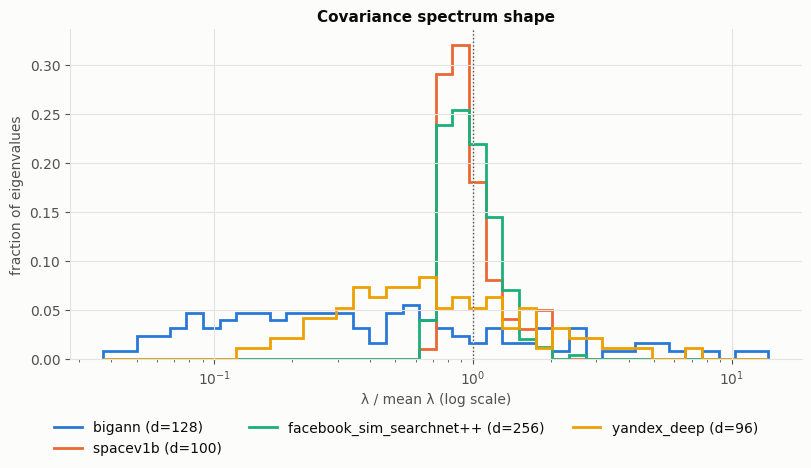

In [4]:
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]   # fixed categorical order
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})
assert len(spectra) <= len(SERIES), "more datasets than series colors: plot them in groups"

BINS = 40           # log-spaced bins over all datasets' normalised eigenvalues
ZERO = 1e-12        # eigenvalues below ZERO * mean are treated as zero

norm = {name: lam / lam.mean() for name, (lam, _) in spectra.items()}
for name, x in norm.items():
    if (x <= ZERO).any():
        print(f"{name}: {(x <= ZERO).sum()} of {len(x)} eigenvalues are ~0 (not shown)")
pos = np.concatenate([x[x > ZERO] for x in norm.values()]) if norm else np.ones(1)
edges = np.geomspace(pos.min(), pos.max(), BINS + 1)

fig, ax = plt.subplots(figsize=(8, 4.6), constrained_layout=True)
for color, (name, x) in zip(SERIES, norm.items()):
    counts, _ = np.histogram(x[x > ZERO], bins=edges)
    ax.stairs(counts / len(x), edges, color=color, lw=2, label=f"{name} (d={len(x)})")
ax.axvline(1, color=INK_2, ls=":", lw=1)
ax.set(xscale="log", xlabel="λ / mean λ (log scale)", ylabel="fraction of eigenvalues",
       title="Covariance spectrum shape")
fig.legend(*ax.get_legend_handles_labels(), loc="outside lower center", ncol=min(3, len(norm)), frameon=False)
if SAVE and spectra:
    fig.savefig(RESULTS_DIR / "spectra" / "spectrum_hist.png", dpi=160)
plt.show()

In [ ]:
# effdim.to_csv(RESULTS_DIR / "effective_dimension.csv", index=False)

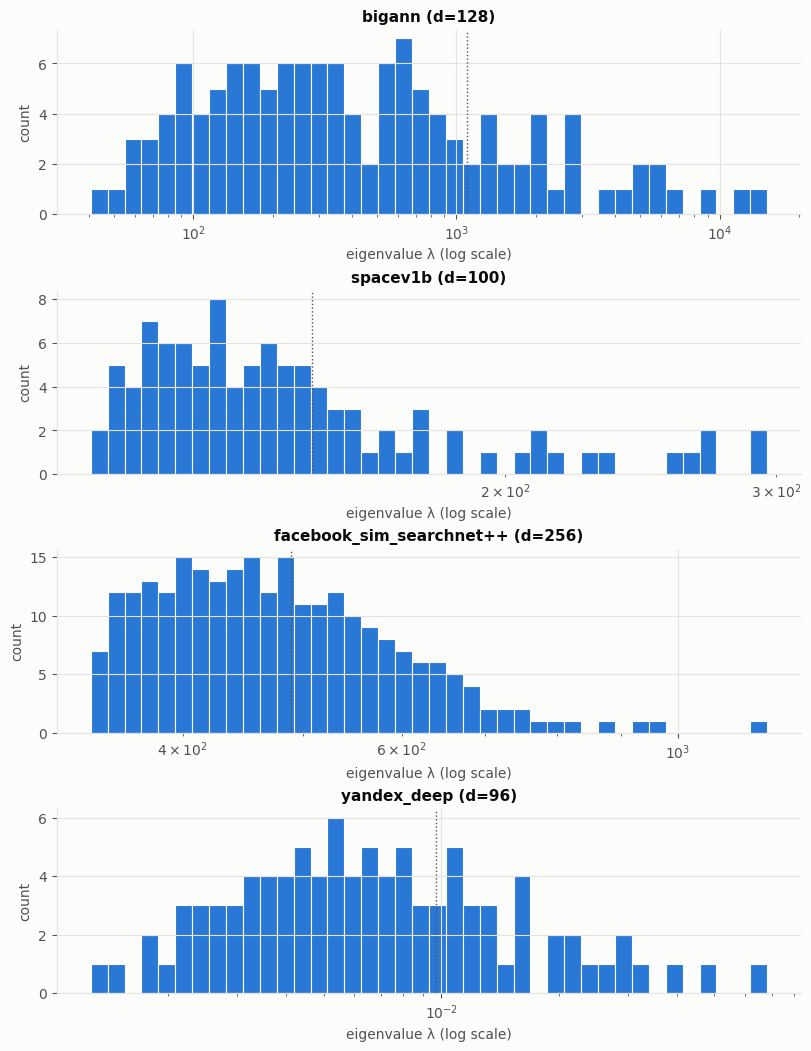

In [5]:
import matplotlib.pyplot as plt
import numpy as np

BINS = 40
LOG_X = True        # eigenvalues usually span several orders of magnitude; False for linear bins

names = list(spectra)
fig, axes = plt.subplots(len(names), 1, figsize=(8, 2.6 * len(names)), squeeze=False, constrained_layout=True)
for ax, name in zip(axes[:, 0], names):
    lam = spectra[name][0]                      # eigenvalues, largest first
    if LOG_X:
        pos = lam[lam > 0]
        if len(pos) < len(lam):
            print(f"{name}: {len(lam) - len(pos)} zero eigenvalues not shown on the log axis")
        edges = np.geomspace(pos.min(), pos.max(), BINS + 1)
        ax.hist(pos, bins=edges, color="#2a78d6", edgecolor="#fcfcfb", linewidth=0.8)
        ax.set_xscale("log")
    else:
        ax.hist(lam, bins=BINS, color="#2a78d6", edgecolor="#fcfcfb", linewidth=0.8)
    ax.axvline(lam.mean(), color="#52514e", ls=":", lw=1)
    ax.set(title=f"{name} (d={len(lam)})", ylabel="count", xlabel="eigenvalue λ" + (" (log scale)" if LOG_X else ""))
plt.show()


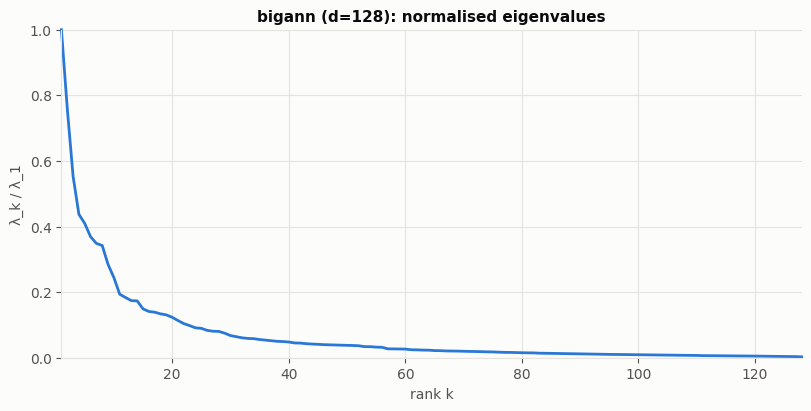

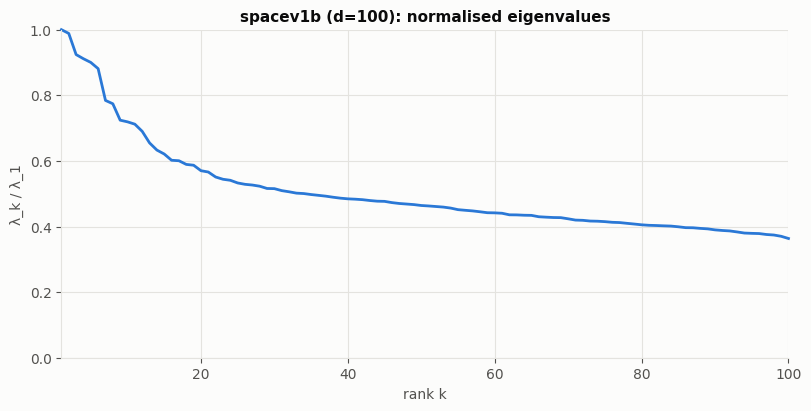

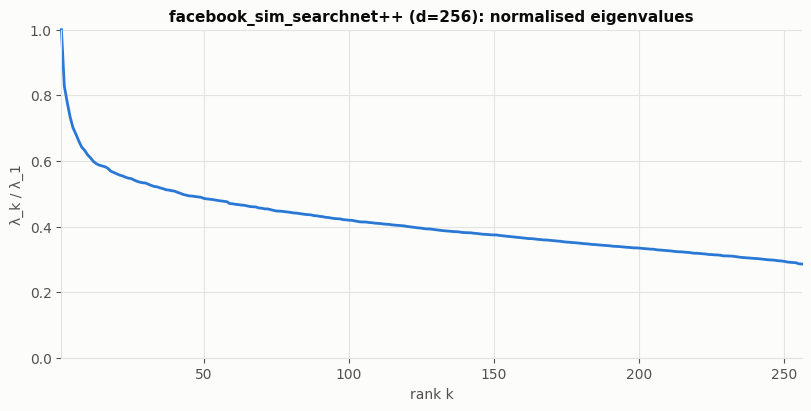

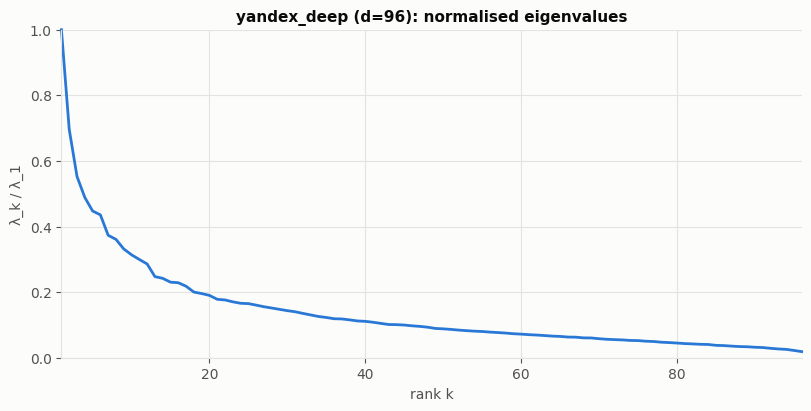

In [8]:
import matplotlib.pyplot as plt
import numpy as np

for name, (lam, _) in spectra.items():
    lam = np.sort(lam)[::-1]                    # decreasing order
    lam = lam / lam[0]                          # largest eigenvalue -> 1
    fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
    ax.plot(np.arange(1, len(lam) + 1), lam, color="#2a78d6", lw=2, clip_on=False)
    ax.set(xlabel="rank k", ylabel="λ_k / λ_1", title=f"{name} (d={len(lam)}): normalised eigenvalues",
           xlim=(1, len(lam)), ylim=(0, 1))
    plt.show()
